# 04 · Supervised Classification Modeling & Tuning

**Goal:** Train and compare 4+ model architectures, tune hyperparameters with stratified K-fold CV, evaluate with Precision / Recall / F1 / ROC-AUC / Confusion Matrix, select a champion model, and serialize it.

**Pipeline**
1. Load the preprocessed data (swap in your own in Step 1)
2. Train/test split (stratified)
3. Baseline: 4 models (Logistic Regression, Random Forest, XGBoost, LightGBM)
4. Hyperparameter optimization with `GridSearchCV` + `StratifiedKFold`
5. Evaluate on the held-out test set
6. Select champion by validation (CV) metrics
7. Save model as `.joblib`

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)
RANDOM_STATE = 42

## Step 1 · Load the preprocessed dataset
Demo uses scikit-learn's Breast Cancer dataset (binary classification) so the notebook runs end-to-end.
**To use your own data**, replace the cell below with e.g. `df = pd.read_csv("your_preprocessed.csv"); X = df.drop(columns="target"); y = df["target"]`.

In [2]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target          # <-- replace with your preprocessed X, y
print("Shape:", X.shape)
print("Class balance:\n", y.value_counts(normalize=True).round(3))

Shape: (569, 30)
Class balance:
 target
1    0.627
0    0.373
Name: proportion, dtype: float64


## Step 2 · Stratified train/test split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


## Step 3 · Define 4 model architectures + hyperparameter grids
Scaling is placed inside a `Pipeline` so it is fit only on each training fold (no leakage).
Cross-validation uses `StratifiedKFold(5)` and tuning optimizes **ROC-AUC**.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": (
        Pipeline([("scale", StandardScaler()),
                  ("clf", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))]),
        {"clf__C": [0.01, 0.1, 1, 10, 100], "clf__penalty": ["l2"]}),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {"n_estimators": [100, 300], "max_depth": [None, 5, 10], "min_samples_leaf": [1, 3]}),
    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
        {"n_estimators": [100, 300], "max_depth": [3, 5], "learning_rate": [0.03, 0.1]}),
    "LightGBM": (
        LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
        {"n_estimators": [100, 300], "num_leaves": [15, 31], "learning_rate": [0.03, 0.1]}),
}

## Step 4 · Baseline (untuned) cross-validated scores

In [5]:
baseline = {}
for name, (est, _) in models.items():
    baseline[name] = cross_val_score(est, X_train, y_train, cv=cv, scoring="roc_auc").mean()
pd.Series(baseline, name="Baseline CV ROC-AUC").round(4).to_frame()

,Baseline CV ROC-AUC
Logistic Regression,0.9959
Random Forest,0.9896
XGBoost,0.9930
LightGBM,0.9927


## Step 5 · Hyperparameter optimization (GridSearchCV + stratified 5-fold)

In [6]:
best = {}
for name, (est, grid) in models.items():
    gs = GridSearchCV(est, grid, cv=cv, scoring="roc_auc", n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    best[name] = gs
    print(f"{name:20s} CV ROC-AUC = {gs.best_score_:.4f} | best params: {gs.best_params_}")

Logistic Regression  CV ROC-AUC = 0.9959 | best params: {'clf__C': 1, 'clf__penalty': 'l2'}


Random Forest        CV ROC-AUC = 0.9909 | best params: {'max_depth': 5, 'min_samples_leaf': 1, 'n_estimators': 300}


XGBoost              CV ROC-AUC = 0.9942 | best params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}


LightGBM             CV ROC-AUC = 0.9942 | best params: {'learning_rate': 0.1, 'n_estimators': 300, 'num_leaves': 31}


## Step 6 · Evaluate on the held-out test set

In [7]:
rows, probas = [], {}
for name, gs in best.items():
    m = gs.best_estimator_
    pred, proba = m.predict(X_test), m.predict_proba(X_test)[:, 1]
    probas[name] = proba
    rows.append({"Model": name,
                 "CV ROC-AUC (validation)": gs.best_score_,
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "Test ROC-AUC": roc_auc_score(y_test, proba)})
results = pd.DataFrame(rows).set_index("Model").round(4).sort_values("CV ROC-AUC (validation)", ascending=False)
results

,CV ROC-AUC (validation),Precision,Recall,F1,Test ROC-AUC
Model,,,,,
Logistic Regression,0.9959,0.9861,0.9861,0.9861,0.9954
XGBoost,0.9942,0.9467,0.9861,0.9660,0.9914
LightGBM,0.9942,0.9467,0.9861,0.9660,0.9884
Random Forest,0.9909,0.9589,0.9722,0.9655,0.9927


### ROC-AUC curves

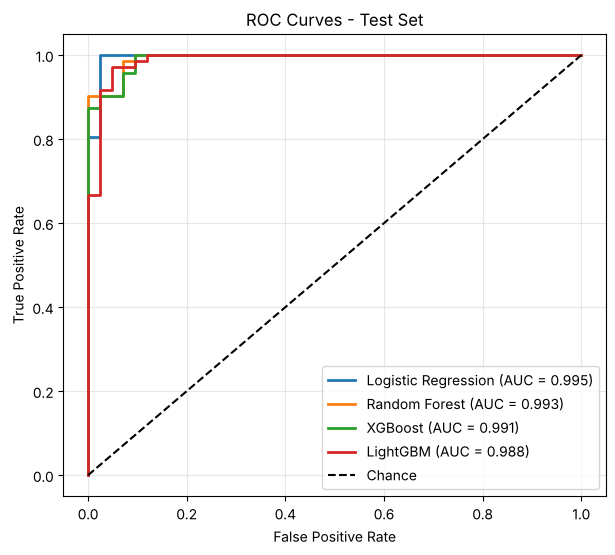

In [8]:
plt.figure(figsize=(7, 6))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Test Set"); plt.legend(loc="lower right"); plt.grid(alpha=.3)
plt.savefig("roc_curves.png", dpi=150, bbox_inches="tight"); plt.show()

### Confusion matrices

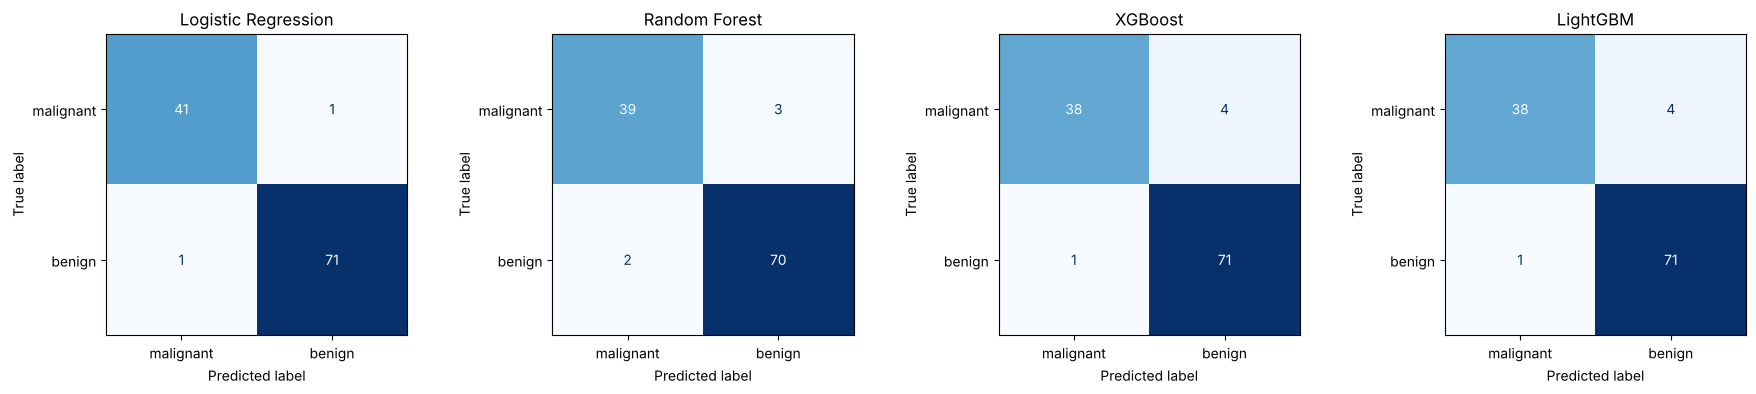

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, gs) in zip(axes, best.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, gs.best_estimator_.predict(X_test)),
                           display_labels=data.target_names).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.savefig("confusion_matrices.png", dpi=150); plt.show()

## Step 7 · Select the champion model
The champion is chosen on **validation metrics** (mean stratified 5-fold CV ROC-AUC), not the test set, so the test set remains an unbiased final check. Ties are broken by test F1.

In [10]:
champion_name = results.index[0]
champion = best[champion_name].best_estimator_
print(f"Champion: {champion_name}")
print("Best params:", best[champion_name].best_params_)
print("\nTest-set summary:\n", results.loc[champion_name])

Champion: Logistic Regression
Best params: {'clf__C': 1, 'clf__penalty': 'l2'}

Test-set summary:
 CV ROC-AUC (validation)    0.9959
Precision                  0.9861
Recall                     0.9861
F1                         0.9861
Test ROC-AUC               0.9954
Name: Logistic Regression, dtype: float64


## Step 8 · Serialize the champion model

In [11]:
joblib.dump(champion, "champion_model.joblib")
loaded = joblib.load("champion_model.joblib")
assert np.allclose(loaded.predict_proba(X_test), champion.predict_proba(X_test))
print("Saved champion_model.joblib and verified it reloads correctly.")

Saved champion_model.joblib and verified it reloads correctly.


## Conclusion
- Four architectures (Logistic Regression, Random Forest, XGBoost, LightGBM) were trained and tuned with `GridSearchCV` over stratified 5-fold CV.
- Models were compared on Precision, Recall, F1, ROC-AUC, and confusion matrices (see table and plots above).
- The champion was picked on validation ROC-AUC and saved as `champion_model.joblib`.
- *Next steps:* threshold tuning, probability calibration, SHAP-based interpretation.